# Diabetes Care Journey: can a few questions and a tape measure find hidden diabetes?

This notebook uses real US health-survey data (**NHANES**, free and public) to build and **honestly evaluate** screening models along the diabetes care journey:

| Module | Question | Who is in the table | Label |
|---|---|---|---|
| **1. Screening** | Normal, prediabetes, or diabetes without knowing it? | Adults who answered **"no"** to "ever told you have diabetes" | HbA1c < 5.7 normal · 5.7–6.4 prediabetes · ≥ 6.5 undiagnosed diabetes |
| **2. Control** | Is this patient's sugar poorly controlled? | Adults **diagnosed** with diabetes | HbA1c ≥ 8% |
| **3. Kidney** | Early diabetic kidney disease? | Adults with diabetes (diagnosed or HbA1c ≥ 6.5) | Urine albumin-creatinine ratio ≥ 30 mg/g **or** eGFR < 60 |

**The questions this notebook answers**
1. How many US adults have diabetes without knowing it, and how many of them were never even tested? (survey-weighted, with confidence intervals)
2. Does machine learning beat the paper risk scores doctors already use, the **Indian Diabetes Risk Score (IDRS)** and the **ADA risk test**? By how much, and for whom?
3. Are the predicted risks trustworthy (calibration), and is the model fair across sex, ethnicity and income?
4. Can the model become an **integer points card** that a community health worker (ASHA) can fill in on paper?
5. Does a model trained on 2017–2020 still work on 2021–2023 data?

**Golden rule:** lab values (HbA1c, creatinine, ACR, eGFR) are used **only to make labels, never as model inputs**. The whole point is predicting without a lab test.

Run the cells from top to bottom (*Runtime → Run all* in Colab). The first run downloads about 40 MB from the CDC (1–3 minutes); later runs use the cached files in `nhanes_raw/`.

<details><summary><b>What changed from version 1</b></summary>

- **Survey design kept.** Exam weights (`WTMECPRP` / `WTMEC2YR`), strata and PSU are carried through, so population percentages are correct and come with confidence intervals.
- **"Borderline" answers handled.** `DIQ010 = 3` (told borderline diabetes) was being counted as "not diagnosed". These people are now excluded from Module 1 by default (switch: `INCLUDE_BORDERLINE`).
- **`DID040 = 666`** ("diagnosed less than a year ago") now maps to 0 years since diagnosis instead of missing.
- **Gestational diabetes** (`RHQ162`) added, because the ADA risk test asks about it.
- **Downloads are cached** and library versions are printed, so anyone can rerun the analysis.
- **No `class_weight="balanced"`.** Re-weighting classes distorts predicted risks. Imbalance is handled by choosing the threshold instead, which keeps risks calibrated.
</details>

## 0. Setup

In [1]:
# Colab already has pandas, numpy, scikit-learn and matplotlib. SHAP is optional (used in section 5f).
try:
    import shap  # noqa: F401
except ImportError:
    %pip install -q shap

In [2]:
import io
import json
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
CACHE = "nhanes_raw"          # downloaded CDC files are kept here
RESULTS = "results"           # metrics, figures and the points card are written here
os.makedirs(RESULTS, exist_ok=True)
RESULTS_JSON = {}             # headline numbers, saved at the end

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

python 3.14.3 | pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.8.0 | scipy 1.17.1


### 0a. Download (cached)

In [3]:
CYCLES = {
    # 2017 - March 2020 "pre-pandemic" cycle: main training data (has family history)
    "2017-2020": {"folder": "2017", "suffix": "", "prefix": "P_", "mec_weight": "WTMECPRP"},
    # Aug 2021 - Aug 2023 cycle: later-years test data (family history question dropped)
    "2021-2023": {"folder": "2021", "suffix": "_L", "prefix": "", "mec_weight": "WTMEC2YR"},
}

# base name -> what it holds
FILES = {
    "DEMO": "demographics, survey weights and design",
    "BMX": "body measures (weight, height, BMI, waist)",
    "BPXO": "blood pressure readings (oscillometric)",
    "BPQ": "BP / cholesterol history and medicines",
    "DIQ": "diabetes questionnaire",
    "MCQ": "medical conditions (family history, heart attack, stroke)",
    "SMQ": "smoking",
    "PAQ": "physical activity",
    "RHQ": "reproductive health (diabetes during pregnancy)",
    "GHB": "HbA1c (lab, label only)",
    "BIOPRO": "blood biochemistry: creatinine (lab, label only)",
    "ALB_CR": "urine albumin-creatinine ratio (lab, label only)",
}


def file_name(base, cycle):
    c = CYCLES[cycle]
    return f"{c['prefix']}{base}{c['suffix']}"


def download_cycle(cycle, bases=FILES):
    """Return {base: DataFrame}. Files are cached in nhanes_raw/<cycle>/ after the first download."""
    import requests

    c = CYCLES[cycle]
    folder = os.path.join(CACHE, cycle)
    os.makedirs(folder, exist_ok=True)
    out = {}
    for base in bases:
        name = file_name(base, cycle)
        path = os.path.join(folder, f"{name}.xpt")
        source = "cached"
        if not os.path.exists(path):
            content = None
            for ext in ("xpt", "XPT"):  # CDC has used both spellings
                url = f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{c['folder']}/DataFiles/{name}.{ext}"
                try:
                    r = requests.get(url, timeout=120)
                    if (r.status_code == 200 and len(r.content) > 1000
                            and not r.content[:15].lower().startswith(b"<!doctype")):
                        content = r.content
                        break
                except Exception as e:  # network hiccup: try the next URL
                    print(f"   {url}: {e}")
            if content is None:
                print(f"!! {name}: could not download - check the file name on the NHANES website")
                continue
            with open(path, "wb") as f:
                f.write(content)
            source = "downloaded"
        df = pd.read_sas(path, format="xport")
        df.columns = [name_.upper() for name_ in df.columns]  # MCQ300c -> MCQ300C
        out[base] = df
        print(f"ok {name:12s} {len(df):6d} rows  {source:10s} ({FILES.get(base, '')})")
    return out

### 0b. Build one clean table per person

In [4]:
SOURCE_VARS = ["RIDAGEYR", "RIAGENDR", "RIDRETH3", "DMDEDUC2", "INDFMPIR", "RIDEXPRG", "SDMVSTRA", "SDMVPSU",
               "BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BPXOSY1", "BPXODI1", "MCQ300C", "BPQ020", "BPQ080",
               "SMQ020", "PAQ650", "PAQ665", "PAQ605", "MCQ160E", "MCQ160F", "RHQ162", "DIQ010", "DIQ160",
               "DIQ180", "DIQ050", "DIQ070", "DID040", "LBXGH", "LBXSCR", "URDACT"]


def col(df, name):
    """Column if present, else all-NaN (so a question missing in one cycle doesn't crash)."""
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)


def yes_no(s):
    """NHANES 1=yes, 2=no, 7/9=refused/don't know -> 1 / 0 / NaN."""
    return s.map({1: 1, 2: 0})


def egfr_ckd_epi_2021(scr, age, female):
    """Race-free CKD-EPI 2021 creatinine equation (mL/min/1.73m2)."""
    kappa = np.where(female == 1, 0.7, 0.9)
    alpha = np.where(female == 1, -0.241, -0.302)
    ratio = scr / kappa
    egfr = (142 * np.minimum(ratio, 1) ** alpha * np.maximum(ratio, 1) ** -1.200
            * 0.9938 ** age * np.where(female == 1, 1.012, 1.0))
    return pd.Series(egfr, index=scr.index)


def build_master(dfs, cycle):
    """Merge all files on SEQN and derive clean features + labels for non-pregnant adults 20+."""
    m = dfs["DEMO"].copy()
    for base, df in dfs.items():
        if base != "DEMO":
            m = m.merge(df, on="SEQN", how="left", suffixes=("", f"_{base}"))
    missing = [v for v in SOURCE_VARS + [CYCLES[cycle]["mec_weight"]] if v not in m.columns]
    if missing:
        print(f"[{cycle}] not in this cycle (will be empty):", ", ".join(missing))

    d = pd.DataFrame({"SEQN": m["SEQN"].astype(int)})
    # --- survey design (needed for correct population percentages)
    d["mec_weight"] = col(m, CYCLES[cycle]["mec_weight"])
    d["strata"] = col(m, "SDMVSTRA")
    d["psu"] = col(m, "SDMVPSU")

    # --- demographics
    d["age"] = col(m, "RIDAGEYR")          # 80 means 80 or older
    d["female"] = col(m, "RIAGENDR").map({1: 0, 2: 1})
    d["ethnicity"] = col(m, "RIDRETH3").map({1: "Mexican American", 2: "Other Hispanic", 3: "NH White",
                                            4: "NH Black", 6: "NH Asian", 7: "Other/Multi"})
    d["education"] = col(m, "DMDEDUC2").where(col(m, "DMDEDUC2").between(1, 5))
    d["income_poverty_ratio"] = col(m, "INDFMPIR")
    pregnant = col(m, "RIDEXPRG") == 1

    # --- body measures (things a field worker can measure)
    d["weight_kg"] = col(m, "BMXWT")
    d["height_cm"] = col(m, "BMXHT")
    d["bmi"] = col(m, "BMXBMI")
    d["waist_cm"] = col(m, "BMXWAIST")
    d["waist_height_ratio"] = d["waist_cm"] / d["height_cm"]
    d["systolic_bp"] = m[[c for c in ["BPXOSY1", "BPXOSY2", "BPXOSY3"] if c in m]].mean(axis=1)
    d["diastolic_bp"] = m[[c for c in ["BPXODI1", "BPXODI2", "BPXODI3"] if c in m]].mean(axis=1)

    # --- history questions (things a field worker can ask)
    d["family_history_diabetes"] = yes_no(col(m, "MCQ300C"))  # dropped in the 2021-2023 cycle
    d["told_high_bp"] = yes_no(col(m, "BPQ020"))
    d["told_high_cholesterol"] = yes_no(col(m, "BPQ080"))
    d["ever_smoked_100_cig"] = yes_no(col(m, "SMQ020"))
    d["vigorous_activity"] = yes_no(col(m, "PAQ650"))       # vigorous recreational activity
    d["moderate_activity"] = yes_no(col(m, "PAQ665"))       # moderate recreational activity
    d["exercise"] = d[["vigorous_activity", "moderate_activity"]].max(axis=1)   # any regular exercise
    d["strenuous_work"] = yes_no(col(m, "PAQ605"))          # vigorous work activity
    d["heart_attack"] = yes_no(col(m, "MCQ160E"))
    d["stroke"] = yes_no(col(m, "MCQ160F"))
    # diabetes during pregnancy (asked of women); men can't have it -> 0
    d["gestational_diabetes"] = yes_no(col(m, "RHQ162"))
    d.loc[d["female"] == 0, "gestational_diabetes"] = 0

    # --- diabetes questionnaire
    diq010 = col(m, "DIQ010")
    d["diabetes_answer"] = diq010.map({1: "yes", 2: "no", 3: "borderline"})
    d["diagnosed_diabetes"] = diq010.map({1: 1, 2: 0, 3: 0})   # borderline is NOT diagnosed, but see Module 1
    d["told_prediabetes"] = yes_no(col(m, "DIQ160"))
    d["blood_sugar_tested_3y"] = yes_no(col(m, "DIQ180"))   # asked only of people NOT diagnosed
    d["on_insulin"] = yes_no(col(m, "DIQ050"))
    d["on_diabetes_pills"] = yes_no(col(m, "DIQ070"))
    did040 = col(m, "DID040")                                # age when first told; 666 = under 1 year ago
    age_dx = did040.where(did040.between(1, 80)).mask(did040 == 666, d["age"])
    d["years_since_diagnosis"] = (d["age"] - age_dx).clip(lower=0)

    # --- lab values (used ONLY to make labels, never as model inputs)
    d["hba1c"] = col(m, "LBXGH")
    d["serum_creatinine"] = col(m, "LBXSCR")
    d["urine_acr"] = col(m, "URDACT")
    d["egfr"] = egfr_ckd_epi_2021(d["serum_creatinine"], d["age"], d["female"])

    keep = (d["age"] >= 20) & ~pregnant
    return d[keep].reset_index(drop=True)

### 0c. The three modelling tables

In [5]:
INCLUDE_BORDERLINE = False    # True puts "told borderline diabetes" people into the screening table

SCREEN_FEATURES = ["age", "female", "bmi", "waist_cm", "waist_height_ratio", "weight_kg", "height_cm",
                   "systolic_bp", "diastolic_bp", "family_history_diabetes", "told_high_bp",
                   "told_high_cholesterol", "ever_smoked_100_cig", "vigorous_activity", "moderate_activity",
                   "exercise", "strenuous_work", "gestational_diabetes"]
TREATMENT_FEATURES = ["on_insulin", "on_diabetes_pills", "years_since_diagnosis"]
DIABETIC_FEATURES = SCREEN_FEATURES + TREATMENT_FEATURES + ["heart_attack", "stroke"]
DESIGN = ["mec_weight", "strata", "psu"]
KEEP_FOR_ANALYSIS = ["SEQN", "ethnicity", "education", "income_poverty_ratio"] + DESIGN
# kept for analysis, NOT as model inputs: "how many hidden cases were never tested?"
SCREEN_ANALYSIS = KEEP_FOR_ANALYSIS + ["blood_sugar_tested_3y", "told_prediabetes", "diabetes_answer"]


def module1(d, include_borderline=INCLUDE_BORDERLINE):
    """Not diagnosed, has HbA1c. 0 normal (<5.7), 1 prediabetes (5.7-6.4), 2 undiagnosed diabetes (>=6.5)."""
    answers = ["no", "borderline"] if include_borderline else ["no"]
    t = d[d["diabetes_answer"].isin(answers) & d["hba1c"].notna()].copy()
    t["label"] = pd.cut(t["hba1c"], [0, 5.7, 6.5, 99], right=False, labels=[0, 1, 2]).astype(int)
    t["label_name"] = t["label"].map({0: "normal", 1: "prediabetes", 2: "undiagnosed_diabetes"})
    return t[SCREEN_ANALYSIS + SCREEN_FEATURES + ["hba1c", "label", "label_name"]].reset_index(drop=True)


def module2(d):
    """Diagnosed diabetes, has HbA1c. 1 = poorly controlled (HbA1c >= 8%)."""
    t = d[(d["diabetes_answer"] == "yes") & d["hba1c"].notna()].copy()
    t["label"] = (t["hba1c"] >= 8).astype(int)
    return t[KEEP_FOR_ANALYSIS + DIABETIC_FEATURES + ["hba1c", "label"]].reset_index(drop=True)


def module3(d):
    """Diabetes (diagnosed, or HbA1c >= 6.5) with kidney labs. 1 = DKD (ACR >= 30 mg/g or eGFR < 60)."""
    has_dm = (d["diabetes_answer"] == "yes") | (d["hba1c"] >= 6.5)
    t = d[has_dm & d["urine_acr"].notna() & d["egfr"].notna()].copy()
    t["label"] = ((t["urine_acr"] >= 30) | (t["egfr"] < 60)).astype(int)
    # undiagnosed people have no medicine/duration answers: fill as 0 / 0 years
    undiagnosed = t["diabetes_answer"] != "yes"
    for c in TREATMENT_FEATURES:
        t.loc[undiagnosed, c] = t.loc[undiagnosed, c].fillna(0)
    return t[KEEP_FOR_ANALYSIS + DIABETIC_FEATURES + ["diagnosed_diabetes", "urine_acr", "egfr", "label"]
             ].reset_index(drop=True)


def summarise(name, t):
    print(f"\n=== {name}: {len(t)} people ===")
    print(t["label"].value_counts().sort_index().to_string())
    miss = t.drop(columns=DESIGN, errors="ignore").isna().mean().sort_values(ascending=False)
    miss = miss[miss > 0.05]
    if len(miss):
        print("columns >5% missing:", ", ".join(f"{k} {v:.0%}" for k, v in miss.items()))

### 0d. The paper risk scores doctors already use

Both scores are rebuilt from NHANES answers. Where NHANES asks a slightly different question, the adaptation is written next to the code, so a reviewer can check it.

**Indian Diabetes Risk Score** (Mohan et al., *JAPI* 2005), 0–100, **≥ 60 = high risk**
| Item | Points |
|---|---|
| Age < 35 / 35–49 / ≥ 50 | 0 / 20 / 30 |
| Waist, women < 80 / 80–89 / ≥ 90 cm; men < 90 / 90–99 / ≥ 100 cm | 0 / 10 / 20 |
| Regular exercise **and** strenuous work / either one / neither | 0 / 20 / 30 |
| Family history: none / one parent / both parents | 0 / 10 / 20 |

**ADA diabetes risk test** (Bang et al., *Ann Intern Med* 2009), 0–11, **≥ 5 = high risk**: age (0–3), male (1), diabetes in pregnancy (1), family history (1), high blood pressure (1), not physically active (1), BMI category (0–3). The ADA's version for Asian Americans uses lower BMI cut-offs (23 / 27.5 / 37.5 instead of 25 / 30 / 40).

In [6]:
def idrs(t):
    """Indian Diabetes Risk Score, adapted to NHANES.
    NHANES asks 'any close relative' with diabetes (not 'one or both parents'), so a yes scores 10.
    'Regular exercise' = vigorous or moderate recreational activity; 'strenuous work' = vigorous work activity.
    """
    age = np.select([t["age"] < 35, t["age"] < 50], [0, 20], 30)
    w, f = t["waist_cm"], t["female"] == 1
    waist = np.where(f, np.select([w < 80, w < 90], [0, 10], 20), np.select([w < 90, w < 100], [0, 10], 20))
    waist = np.where(w.isna(), 10, waist)          # unmeasured waist -> middle category
    n_active = (t["exercise"] == 1).astype(int) + (t["strenuous_work"] == 1).astype(int)
    activity = np.select([n_active == 2, n_active == 1], [0, 20], 30)
    family = np.where(t["family_history_diabetes"] == 1, 10, 0)
    return pd.Series(age + waist + activity + family, index=t.index)


def ada_score(t, asian_bmi=False):
    """ADA diabetes risk test. BMI stands in for the paper weight-height chart (it is built from BMI)."""
    age = np.select([t["age"] < 40, t["age"] < 50, t["age"] < 60], [0, 1, 2], 3)
    cut = (23, 27.5, 37.5) if asian_bmi else (25, 30, 40)
    b = t["bmi"]
    bmi = np.select([b < cut[0], b < cut[1], b < cut[2]], [0, 1, 2], 3)
    bmi = np.where(b.isna(), 1, bmi)
    active = (t["exercise"] == 1) | (t["strenuous_work"] == 1)
    score = (age + (t["female"] == 0) + (t["gestational_diabetes"] == 1) + (t["family_history_diabetes"] == 1)
             + (t["told_high_bp"] == 1) + (~active) + bmi)
    return pd.Series(score.astype(int), index=t.index)

### 0e. Evaluation helpers

In [7]:
def auc_ci(y, s, n_boot=500, seed=RANDOM_STATE):
    """AUROC with a percentile-bootstrap 95% CI."""
    y, s = np.asarray(y), np.asarray(s, float)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            boots.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def flag_metrics(y, flag):
    """What happens if everyone flagged gets an HbA1c test."""
    y, flag = np.asarray(y).astype(bool), np.asarray(flag).astype(bool)
    tp = (y & flag).sum()
    return {"sensitivity": tp / y.sum(),
            "specificity": (~y & ~flag).sum() / (~y).sum(),
            "PPV": tp / max(flag.sum(), 1),
            "share_tested": flag.mean(),
            "tests_per_case_found": flag.sum() / max(tp, 1)}


def threshold_for_sensitivity(y, s, target):
    """Highest threshold that still catches at least `target` of the cases."""
    pos = np.sort(np.asarray(s)[np.asarray(y) == 1])[::-1]
    k = int(np.ceil(target * len(pos))) - 1
    return pos[max(k, 0)]


def make_models():
    # No class_weight: re-weighting would inflate every predicted risk. We pick a threshold instead.
    return {
        "Logistic regression": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                             StandardScaler(), LogisticRegression(max_iter=5000)),
        "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_leaf_nodes=8,
                                                            min_samples_leaf=50, l2_regularization=1.0,
                                                            random_state=RANDOM_STATE),
    }


def oof_predictions(X, y, models=None, folds=5):
    """Out-of-fold risk for every person: each prediction comes from a model that never saw that person."""
    skf = StratifiedKFold(folds, shuffle=True, random_state=RANDOM_STATE)
    models = models or make_models()
    return {name: cross_val_predict(mdl, X, y, cv=skf, method="predict_proba")[:, 1]
            for name, mdl in models.items()}


def auc_diff(y, s, ref, n_boot=1000, seed=RANDOM_STATE):
    """AUROC(s) - AUROC(ref) on the same people, with a paired bootstrap 95% CI.
    If the CI includes 0, the data can't tell the two scores apart."""
    y, s, ref = np.asarray(y), np.asarray(s, float), np.asarray(ref, float)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            diffs.append(roc_auc_score(y[i], s[i]) - roc_auc_score(y[i], ref[i]))
    return roc_auc_score(y, s) - roc_auc_score(y, ref), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


def auc_table(y, scores, ref=None):
    """AUROC table; with `ref` (a key of `scores`) adds each score's paired difference from it."""
    rows = []
    for name, s in scores.items():
        auc, lo, hi = auc_ci(y, s)
        row = {"score": name, "AUROC": round(auc, 3), "95% CI": f"{lo:.3f}-{hi:.3f}",
               "AUPRC": round(average_precision_score(y, s), 3)}
        if ref is not None and name != ref:
            dd, dlo, dhi = auc_diff(y, s, scores[ref])
            row[f"vs {ref}"] = f"{dd:+.3f} ({dlo:+.3f} to {dhi:+.3f})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("score").fillna("")

### 0f. Survey-weighted estimates

NHANES deliberately over-samples some groups, so a plain percentage of the sample is **not** a percentage of US adults. This helper gives the weighted estimate and a design-based 95% CI (Taylor linearisation, the same method as R's `survey::svymean` for a subgroup).

In [8]:
def svy_prop(d, y, domain):
    """Weighted mean of 0/1 `y` among rows where `domain` is True, with design-based 95% CI.
    `d` must be the full analysis table (all PSUs present) so subgroup variance is computed correctly."""
    y = pd.Series(y, index=d.index).astype(float)
    dom = pd.Series(domain, index=d.index).fillna(False).astype(bool) & y.notna() & (d["mec_weight"] > 0)
    w = d["mec_weight"].where(dom, 0.0)
    p = (w * y.fillna(0)).sum() / w.sum()
    z = w * (y.fillna(0) - p) / w.sum()
    totals = pd.DataFrame({"h": d["strata"], "j": d["psu"], "z": z}).groupby(["h", "j"])["z"].sum().reset_index()
    var = sum(len(g) / (len(g) - 1) * ((g["z"] - g["z"].mean()) ** 2).sum()
              for _, g in totals.groupby("h") if len(g) > 1)
    dof = totals["j"].count() - totals["h"].nunique()
    half = stats.t.ppf(0.975, dof) * np.sqrt(var)
    return {"estimate": p, "ci_low": max(p - half, 0), "ci_high": min(p + half, 1), "n": int(dom.sum())}


def fmt(r):
    return f"{r['estimate']:.1%} (95% CI {r['ci_low']:.1%}-{r['ci_high']:.1%}, n={r['n']})"

## 1. Download the 2017 – March 2020 cycle

In [9]:
dfs = download_cycle("2017-2020")

ok P_DEMO        15560 rows  cached     (demographics, survey weights and design)
ok P_BMX         14300 rows  cached     (body measures (weight, height, BMI, waist))
ok P_BPXO        11656 rows  cached     (blood pressure readings (oscillometric))
ok P_BPQ         10195 rows  cached     (BP / cholesterol history and medicines)
ok P_DIQ         14986 rows  cached     (diabetes questionnaire)
ok P_MCQ         14986 rows  cached     (medical conditions (family history, heart attack, stroke))


ok P_SMQ         11137 rows  cached     (smoking)
ok P_PAQ          9693 rows  cached     (physical activity)
ok P_RHQ          5314 rows  cached     (reproductive health (diabetes during pregnancy))
ok P_GHB         10409 rows  cached     (HbA1c (lab, label only))
ok P_BIOPRO      10409 rows  cached     (blood biochemistry: creatinine (lab, label only))
ok P_ALB_CR      13027 rows  cached     (urine albumin-creatinine ratio (lab, label only))


## 2. Build the three tables

In [10]:
master = build_master(dfs, "2017-2020")
print("Adults 20+ (not pregnant):", len(master))
print("Diabetes answer:", master["diabetes_answer"].value_counts(dropna=False).to_dict())
print(f"'Borderline' people kept out of Module 1: {(master['diabetes_answer'] == 'borderline').sum()}")

m1 = module1(master); summarise("Module 1: screening", m1)
m2 = module2(master); summarise("Module 2: sugar control", m2)
m3 = module3(master); summarise("Module 3: kidney disease", m3)

Adults 20+ (not pregnant): 9145
Diabetes answer: {'no': 7461, 'yes': 1417, 'borderline': 262, nan: 5}
'Borderline' people kept out of Module 1: 262

=== Module 1: screening: 6504 people ===
label
0    4260
1    2017
2     227
columns >5% missing: income_poverty_ratio 14%, gestational_diabetes 12%, diastolic_bp 10%, systolic_bp 10%

=== Module 2: sugar control: 1257 people ===
label
0    896
1    361
columns >5% missing: income_poverty_ratio 13%, diastolic_bp 10%, systolic_bp 10%, waist_height_ratio 8%, waist_cm 8%, gestational_diabetes 7%

=== Module 3: kidney disease: 1448 people ===
label
0    857
1    591
columns >5% missing: income_poverty_ratio 13%, systolic_bp 9%, diastolic_bp 9%, gestational_diabetes 8%, waist_height_ratio 6%, waist_cm 6%


## 3. Save as CSV files
Files appear in `data/` (in Colab: the folder icon on the left → right-click → Download). The optional second cell copies them to Google Drive.

In [11]:
os.makedirs("data", exist_ok=True)
master.to_csv("data/nhanes_2017_2020_master.csv", index=False)
m1.to_csv("data/module1_screening.csv", index=False)
m2.to_csv("data/module2_control.csv", index=False)
m3.to_csv("data/module3_kidney.csv", index=False)
print(sorted(os.listdir("data")))

['module1_screening.csv', 'module1_screening_2021_2023.csv', 'module2_control.csv', 'module2_control_2021_2023.csv', 'module3_kidney.csv', 'module3_kidney_2021_2023.csv', 'nhanes_2017_2020_master.csv']


In [12]:
# Optional (Colab only): save to Google Drive so the files survive after Colab closes
try:
    from google.colab import drive
    drive.mount("/content/drive")
    out = "/content/drive/MyDrive/diabetes_project"
    for sub in ["data", RESULTS]:
        os.makedirs(f"{out}/{sub}", exist_ok=True)
        for f in os.listdir(sub):
            with open(f"{sub}/{f}", "rb") as src, open(f"{out}/{sub}/{f}", "wb") as dst:
                dst.write(src.read())
    print("Saved to", out)
except ImportError:
    print("Not running in Colab - skipped.")

Not running in Colab - skipped.


## 4. The headline: hidden diabetes in the US population

These are **survey-weighted** estimates, so they describe US adults (20+, not pregnant) in 2017 – March 2020, not just the people in the sample. "Undiagnosed diabetes" means HbA1c ≥ 6.5% in someone who says they were never told they have diabetes (a single test, so a research definition, not a diagnosis).

In [13]:
lab = master["hba1c"].notna() & master["diabetes_answer"].notna()
undiag = (master["diabetes_answer"] != "yes") & (master["hba1c"] >= 6.5)
any_dm = (master["diabetes_answer"] == "yes") | (master["hba1c"] >= 6.5)
prediab = (master["diabetes_answer"] == "no") & master["hba1c"].between(5.7, 6.4999)

headline = {
    "adults with undiagnosed diabetes": svy_prop(master, undiag.astype(float), lab),
    "of everyone with diabetes, share undiagnosed": svy_prop(master, undiag.astype(float), lab & any_dm),
    "undiagnosed diabetes: NO blood test in past 3 years": svy_prop(master, 1 - master["blood_sugar_tested_3y"],
                                                                    lab & undiag),
    "prediabetes range: never told they have prediabetes": svy_prop(master, 1 - master["told_prediabetes"],
                                                                    lab & prediab),
}
for k, r in headline.items():
    print(f"{k:55s} {fmt(r)}")
RESULTS_JSON["headline_2017_2020"] = headline

adults with undiagnosed diabetes                        2.4% (95% CI 2.0%-2.8%, n=8000)
of everyone with diabetes, share undiagnosed            16.8% (95% CI 14.5%-19.1%, n=1541)
undiagnosed diabetes: NO blood test in past 3 years     26.6% (95% CI 20.7%-32.5%, n=280)
prediabetes range: never told they have prediabetes     77.0% (95% CI 73.5%-80.6%, n=2016)


**How to use this in a write-up.** The "no blood test in 3 years" line is the case for a screening tool: these people were not missed by a test, they were never tested at all. Quote the weighted estimate with its CI, never the raw sample percentage.

## 5. Module 1: does ML beat the paper risk scores?

**Target:** undiagnosed diabetes (HbA1c ≥ 6.5) among people who say they don't have diabetes, the same target IDRS and the ADA test were built for.

Every number below is **out-of-fold**: each person's risk comes from a model trained without them (5-fold cross-validation). That is the honest equivalent of a held-out test set, and it uses all the data.

In [14]:
t = m1.copy()
t["y"] = (t["label"] == 2).astype(int)
t["idrs"] = idrs(t)
t["ada"] = ada_score(t)
t["ada_asian_bmi"] = ada_score(t, asian_bmi=True)
y = t["y"].to_numpy()
print(f"{len(t)} people, {y.sum()} with undiagnosed diabetes ({y.mean():.1%} of the sample)")

oof = oof_predictions(t[SCREEN_FEATURES], y)
scores = {"IDRS (4 items)": t["idrs"], "ADA risk test (7 items)": t["ada"], **oof}
m1_auc = auc_table(y, scores, ref="ADA risk test (7 items)")
m1_auc

6504 people, 227 with undiagnosed diabetes (3.5% of the sample)


,AUROC,95% CI,AUPRC,vs ADA risk test (7 items)
score,,,,
IDRS (4 items),0.697,0.663-0.727,0.063,-0.044 (-0.068 to -0.019)
ADA risk test (7 items),0.741,0.714-0.768,0.072,
Logistic regression,0.759,0.729-0.786,0.087,+0.018 (-0.005 to +0.039)
Gradient boosting,0.725,0.692-0.758,0.089,-0.016 (-0.042 to +0.010)


**Reading the table.** The last column is the paired difference from the ADA test with its 95% CI. If that interval crosses 0, the data can't tell the model and the ADA test apart, and that is a finding worth stating plainly: a 7-question paper test gets most of the way there.

### 5a. At a practical threshold: who gets tested, who is caught?

AUROC is abstract. A clinic or ASHA programme needs to know: *if we send everyone above the cut-off for an HbA1c test, how many tests do we need per case found, and what share of cases do we catch?* Each ML model's threshold is set to catch **the same share of cases as the ADA test does**, so the only difference is how many people need a test.

In [15]:
rows = {"IDRS >= 60": flag_metrics(y, t["idrs"] >= 60),
        "ADA >= 5": flag_metrics(y, t["ada"] >= 5)}
target_sens = rows["ADA >= 5"]["sensitivity"]
thresholds = {}
for name, s in oof.items():
    thresholds[name] = threshold_for_sensitivity(y, s, target_sens)
    rows[f"{name} (same sensitivity as ADA)"] = flag_metrics(y, s >= thresholds[name])
m1_thresh = pd.DataFrame(rows).T
m1_thresh.style.format({"sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}",
                        "share_tested": "{:.1%}", "tests_per_case_found": "{:.1f}"})

,sensitivity,specificity,PPV,share_tested,tests_per_case_found
IDRS >= 60,86.3%,40.5%,5.0%,60.4%,20.0
ADA >= 5,83.3%,55.0%,6.3%,46.3%,15.9
Logistic regression (same sensitivity as ADA),83.3%,53.7%,6.1%,47.6%,16.4
Gradient boosting (same sensitivity as ADA),83.3%,46.2%,5.3%,54.9%,18.9


### 5b. Are the predicted risks real risks? (calibration)

If the model says "8% risk" for a group, about 8% of that group should have undiagnosed diabetes. The diagonal line is perfect calibration.

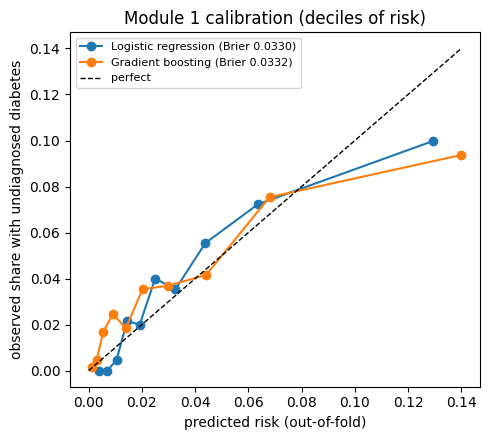

In [16]:
fig, ax = plt.subplots(figsize=(5, 4.5))
lim = 0
for name, s in oof.items():
    frac, mean_pred = calibration_curve(y, s, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", label=f"{name} (Brier {brier_score_loss(y, s):.4f})")
    lim = max(lim, frac.max(), mean_pred.max())
ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect")
ax.set_xlabel("predicted risk (out-of-fold)")
ax.set_ylabel("observed share with undiagnosed diabetes")
ax.set_title("Module 1 calibration (deciles of risk)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{RESULTS}/module1_calibration.png", dpi=150)
plt.show()

### 5c. Fairness: does it work equally well for everyone?

Sensitivity uses the thresholds from 5a. A group with low sensitivity is a group whose hidden cases the tool would miss. Groups with fewer than 15 cases are too small to judge, so their AUROC is left blank.

In [17]:
best = max(oof, key=lambda k: roc_auc_score(y, oof[k]))
risk, thr = oof[best], thresholds[best]
groups = {
    "sex": t["female"].map({0: "male", 1: "female"}),
    "ethnicity": t["ethnicity"],
    "income (poverty ratio)": pd.cut(t["income_poverty_ratio"], [-1, 1.3, 3.5, 99],
                                     labels=["< 1.3 (low)", "1.3-3.5", "> 3.5 (high)"]),
    "age": pd.cut(t["age"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"]),
}
fair = []
for gname, g in groups.items():
    for level in g.dropna().unique():
        i = (g == level).to_numpy()
        n_cases = int(y[i].sum())
        row = {"group": gname, "level": level, "n": int(i.sum()), "cases": n_cases,
               f"AUROC {best}": roc_auc_score(y[i], risk[i]) if n_cases >= 15 else np.nan,
               "AUROC ADA": roc_auc_score(y[i], t["ada"].to_numpy()[i]) if n_cases >= 15 else np.nan,
               f"sensitivity {best}": (risk[i][y[i] == 1] >= thr).mean() if n_cases else np.nan,
               "sensitivity ADA>=5": (t["ada"].to_numpy()[i][y[i] == 1] >= 5).mean() if n_cases else np.nan}
        fair.append(row)
m1_fair = pd.DataFrame(fair).set_index(["group", "level"]).sort_index()
m1_fair.round(3)

n  cases  AUROC Logistic regression  AUROC ADA  sensitivity Logistic regression  sensitivity ADA>=5
group                  level                                                                                                                   
age                    20-39             2273     28                      0.857      0.792                            0.714               0.393
                       40-59             2199    100                      0.716      0.721                            0.800               0.820
                       60+               2032     99                      0.687      0.663                            0.899               0.970
ethnicity              Mexican American   760     38                      0.770      0.770                            0.816               0.789
                       NH Asian           776     36                      0.765      0.791                            0.694               0.722
                       NH Black          1637     73                      0.730      0.743                            0.836               0.890
                       NH White          2339     36                      0.803      0.770                            0.944               0.917
                       Other Hispanic     685     33                      0.795      0.736                            0.879               0.818
                       Other/Multi        307     11                        NaN        NaN                            0.818               0.727
income (poverty ratio) 1.3-3.5           2185     78                      0.726      0.703                            0.808               0.808
                       < 1.3 (low)       1561     61                      0.772      0.749                            0.820               0.787
                       > 3.5 (high)      1869     58                      0.768      0.782                            0.828               0.897
sex                    female            3420    130                      0.808      0.784                            0.915               0.838
                       male              3084     97                      0.689      0.689                            0.722               0.825

#### Closing the gap for men

With one threshold for everyone, the model catches fewer hidden cases in men than the ADA test does. One fix is a **separate threshold for each sex**, each set to catch the same share of cases as the ADA test. The cost is shown honestly: how many more people need a test.

In [18]:
sex = t["female"].to_numpy()
thr_sex = {s: threshold_for_sensitivity(y[sex == s], risk[sex == s], target_sens) for s in (0, 1)}
flag_one = risk >= thr
flag_sex = np.where(sex == 1, risk >= thr_sex[1], risk >= thr_sex[0])
flag_ada = t["ada"].to_numpy() >= 5
sex_rows = []
for rule, flag in [("ADA >= 5", flag_ada), (f"{best}, one threshold", flag_one),
                   (f"{best}, threshold per sex", flag_sex)]:
    for s, s_name in [(0, "men"), (1, "women"), (None, "everyone")]:
        i = np.ones(len(y), bool) if s is None else sex == s
        r = flag_metrics(y[i], flag[i])
        sex_rows.append({"rule": rule, "group": s_name, "sensitivity": r["sensitivity"],
                         "share_tested": r["share_tested"], "tests_per_case_found": r["tests_per_case_found"]})
m1_sex = pd.DataFrame(sex_rows).set_index(["rule", "group"])
m1_sex.style.format({"sensitivity": "{:.1%}", "share_tested": "{:.1%}", "tests_per_case_found": "{:.1f}"})

### 5d. What drives the model? (SHAP)

SHAP shows how much each answer pushes a person's predicted risk up or down. Check that the drivers make clinical sense (age, waist, BP), which is a sanity check as much as an explanation.

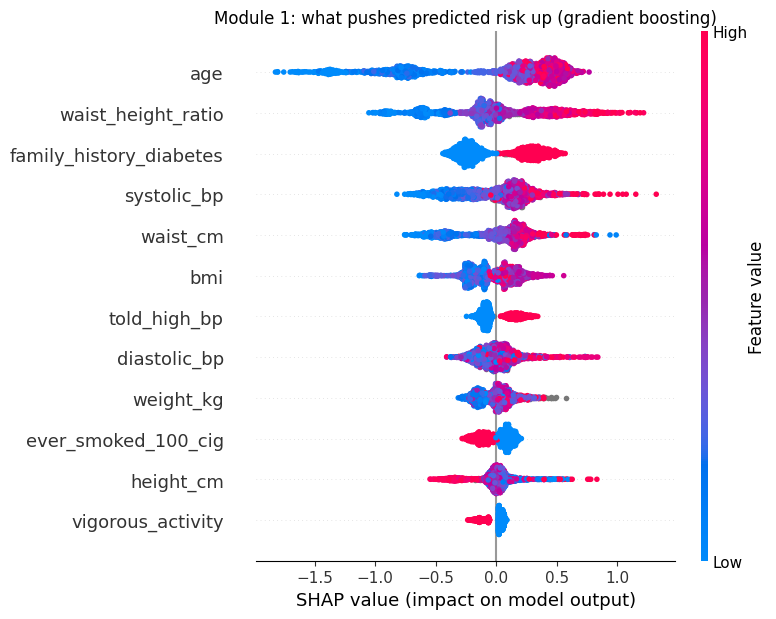

age                        0.5066
waist_height_ratio         0.3285
family_history_diabetes    0.2690
systolic_bp                0.2396
waist_cm                   0.2303
bmi                        0.1577
told_high_bp               0.1178
diastolic_bp               0.1164
weight_kg                  0.1054
ever_smoked_100_cig        0.1035
dtype: float64

In [19]:
gb = make_models()["Gradient boosting"].fit(t[SCREEN_FEATURES], y)
try:
    import shap
    sample = t[SCREEN_FEATURES].sample(min(2000, len(t)), random_state=RANDOM_STATE)
    sv = shap.TreeExplainer(gb).shap_values(sample)
    shap.summary_plot(sv, sample, show=False, max_display=12)
    plt.title("Module 1: what pushes predicted risk up (gradient boosting)")
    plt.tight_layout()
    plt.savefig(f"{RESULTS}/module1_shap.png", dpi=150, bbox_inches="tight")
    plt.show()
    importance = pd.Series(np.abs(sv).mean(axis=0), index=SCREEN_FEATURES).sort_values(ascending=False)
except Exception as e:  # SHAP not installed or unsupported: fall back to permutation importance
    from sklearn.inspection import permutation_importance
    print("SHAP unavailable, using permutation importance:", e)
    pi = permutation_importance(gb, t[SCREEN_FEATURES], y, scoring="roc_auc", n_repeats=5,
                                random_state=RANDOM_STATE)
    importance = pd.Series(pi.importances_mean, index=SCREEN_FEATURES).sort_values(ascending=False)
importance.head(10).round(4)

### 5e. Secondary target: anyone who should get tested (prediabetes or diabetes)

HbA1c ≥ 5.7 is far more common, and a positive result still leads to useful advice (diet, activity, re-test). Same comparison, one table.

In [20]:
y_any = (t["label"] >= 1).astype(int).to_numpy()
oof_any = oof_predictions(t[SCREEN_FEATURES], y_any)
print(f"{y_any.sum()} of {len(y_any)} have HbA1c >= 5.7 ({y_any.mean():.1%})")
m1_any_auc = auc_table(y_any, {"IDRS (4 items)": t["idrs"], "ADA risk test (7 items)": t["ada"], **oof_any},
                       ref="ADA risk test (7 items)")
m1_any_auc

2244 of 6504 have HbA1c >= 5.7 (34.5%)


,AUROC,95% CI,AUPRC,vs ADA risk test (7 items)
score,,,,
IDRS (4 items),0.694,0.682-0.706,0.495,-0.029 (-0.039 to -0.021)
ADA risk test (7 items),0.723,0.711-0.736,0.525,
Logistic regression,0.733,0.721-0.744,0.548,+0.010 (+0.003 to +0.016)
Gradient boosting,0.732,0.721-0.743,0.557,+0.009 (+0.001 to +0.016)


## 6. A points card an ASHA worker can fill in on paper

A logistic model is fitted on **six things a field worker can collect with a weighing scale, a tape measure and a conversation**: age, sex, body size, family history, told high blood pressure, and physical activity. Each coefficient is turned into whole points, **2 points ≈ doubling the odds**, and points are never allowed to go *down* as age or body size goes up (so the card stays believable).

**Which body measure?** Two versions are compared: BMI (needs a scale) and waist-to-height ratio (needs only a tape; often recommended for Asian body types). The data decides, not the literature, and the result is reported either way.

The card's accuracy is measured out-of-fold too: in each fold the card is re-derived from the training part and scored on the held-out part.

In [21]:
AGE_BAND = ([20, 35, 45, 55, 65, 200], ["20-34", "35-44", "45-54", "55-64", "65+"])
BODY_BANDS = {
    "bmi": ([0, 25, 30, 35, 40, 999], ["< 25", "25-29.9", "30-34.9", "35-39.9", "40+"]),
    "waist_height_ratio": ([0, 0.50, 0.55, 0.60, 0.65, 9], ["< 0.50", "0.50-0.54", "0.55-0.59", "0.60-0.64",
                                                           "0.65+"]),
}
CARD_YES_NO = {"male": "Male",
               "family_history_diabetes": "Parent, brother or sister with diabetes",
               "told_high_bp": "Ever told by a doctor you have high blood pressure",
               "inactive": "No regular exercise AND no physically hard work"}


def card_bands(body):
    return {"age": AGE_BAND, body: BODY_BANDS[body]}


def card_design(t, body):
    """0/1 columns for the card. Unanswered yes/no questions count as 'no'."""
    X = pd.DataFrame(index=t.index)
    for var, (bins, labels) in card_bands(body).items():
        band = pd.cut(t[var], bins, right=False, labels=labels)
        for lab_ in labels[1:]:                 # first band is the reference (0 points)
            X[f"{var}={lab_}"] = (band == lab_).astype(int)
    X["male"] = (t["female"] == 0).astype(int)
    X["family_history_diabetes"] = (t["family_history_diabetes"] == 1).astype(int)
    X["told_high_bp"] = (t["told_high_bp"] == 1).astype(int)
    X["inactive"] = ~((t["exercise"] == 1) | (t["strenuous_work"] == 1))
    return X.astype(int)


def fit_card(X, y, body):
    lr = LogisticRegression(C=1e4, max_iter=5000).fit(X, y)
    pts = pd.Series(np.clip(np.round(lr.coef_[0] * 2 / np.log(2)), 0, None).astype(int), index=X.columns)
    for var, (_, labels) in card_bands(body).items():   # monotone: higher band never scores fewer points
        cols_ = [f"{var}={lab_}" for lab_ in labels[1:]]
        pts[cols_] = np.maximum.accumulate(pts[cols_].to_numpy())
    return pts


def card_oof_scores(tc, body):
    X, yy = card_design(tc, body), tc["y"].to_numpy()
    s = np.zeros(len(tc))
    for train, test in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, yy):
        s[test] = X.iloc[test].to_numpy() @ fit_card(X.iloc[train], yy[train], body).to_numpy()
    return s


# compare the two body measures on the same people (everyone with weight, height and waist measured)
tc = t[t["waist_height_ratio"].notna() & t["bmi"].notna()].copy()
yc = tc["y"].to_numpy()
variant_scores = {f"Card with {b}": card_oof_scores(tc, b) for b in BODY_BANDS}
variant_auc = auc_table(yc, {**variant_scores, "ADA risk test (7 items)": tc["ada"]}, ref="ADA risk test (7 items)")
display(variant_auc)
CARD_BODY = max(BODY_BANDS, key=lambda b: roc_auc_score(yc, variant_scores[f"Card with {b}"]))
print("Body measure used for the card:", CARD_BODY)

Xc = card_design(tc, CARD_BODY)
card_oof = variant_scores[f"Card with {CARD_BODY}"]
card = fit_card(Xc, yc, CARD_BODY)
tc["card_score"] = Xc.to_numpy() @ card.to_numpy()
n_items = len(card_bands(CARD_BODY)) + sum(card[k] > 0 for k in CARD_YES_NO)
CARD_NAME = f"Points card ({n_items} items, out-of-fold)"
card_auc = auc_table(yc, {CARD_NAME: card_oof, "IDRS (4 items)": tc["idrs"], "ADA risk test (7 items)": tc["ada"],
                          "Gradient boosting (18 inputs)": oof["Gradient boosting"][tc.index]},
                     ref="ADA risk test (7 items)")
card_auc

,AUROC,95% CI,AUPRC,vs ADA risk test (7 items)
score,,,,
Card with bmi,0.741,0.709-0.771,0.074,-0.004 (-0.024 to +0.014)
Card with waist_height_ratio,0.714,0.685-0.741,0.064,-0.031 (-0.055 to -0.006)
ADA risk test (7 items),0.745,0.719-0.773,0.072,


Body measure used for the card: bmi


,AUROC,95% CI,AUPRC,vs ADA risk test (7 items)
score,,,,
"Points card (5 items, out-of-fold)",0.741,0.709-0.771,0.074,-0.004 (-0.024 to +0.014)
IDRS (4 items),0.696,0.664-0.725,0.063,-0.049 (-0.074 to -0.024)
ADA risk test (7 items),0.745,0.719-0.773,0.072,
Gradient boosting (18 inputs),0.725,0.693-0.759,0.091,-0.020 (-0.045 to +0.009)


### 6a. Choosing the cut-off

Each row: "if everyone with this score or more is sent for an HbA1c test". The suggested cut-off is the highest score that still catches at least as many cases as ADA ≥ 5 does.

In [22]:
cut_rows = []
for c in range(int(tc["card_score"].max()) + 1):
    r = flag_metrics(yc, tc["card_score"] >= c)
    cut_rows.append({"score >=": c, **r})
cuts = pd.DataFrame(cut_rows).set_index("score >=")
ada_sens_tc = flag_metrics(yc, tc["ada"] >= 5)["sensitivity"]
CARD_CUTOFF = int(cuts.index[cuts["sensitivity"] >= ada_sens_tc].max())
print(f"Suggested cut-off: {CARD_CUTOFF} points (ADA >= 5 catches {ada_sens_tc:.0%} of cases in this table)")
cuts.style.format({"sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}",
                   "share_tested": "{:.1%}", "tests_per_case_found": "{:.1f}"})

Suggested cut-off: 7 points (ADA >= 5 catches 83% of cases in this table)


,sensitivity,specificity,PPV,share_tested,tests_per_case_found
score >=,,,,,
0,100.0%,0.0%,3.4%,100.0%,29.1
1,100.0%,4.7%,3.6%,95.5%,27.7
2,99.1%,12.2%,3.9%,88.1%,25.8
3,98.6%,15.7%,4.0%,84.8%,25.0
4,98.6%,16.6%,4.0%,83.9%,24.7
5,98.1%,22.5%,4.3%,78.2%,23.2
6,95.8%,35.5%,5.0%,65.6%,19.9
7,89.7%,49.0%,5.9%,52.3%,16.9
8,78.0%,58.4%,6.3%,42.9%,16.0


In [23]:
# Observed rates by score band (unweighted sample rates; used by predict.py's "people like you" message)
band = np.where(tc["card_score"] >= CARD_CUTOFF, "high", "low")
band_rates = {b: {"undiagnosed_diabetes": float(tc.loc[band == b, "y"].mean()),
                  "hba1c_5_7_or_more": float((tc.loc[band == b, "label"] >= 1).mean()),
                  "n": int((band == b).sum())} for b in ["low", "high"]}

bands_spec = {var: {"edges": bins, "labels": labels,
                    "points": [0] + [int(card[f"{var}={lab_}"]) for lab_ in labels[1:]]}
              for var, (bins, labels) in card_bands(CARD_BODY).items()}
yes_no_spec = {k: {"question": q, "points": int(card[k])} for k, q in CARD_YES_NO.items() if card[k] > 0}
points_card = {
    "description": "NHANES 2017-2020 diabetes screening points card (target: undiagnosed diabetes, HbA1c >= 6.5)",
    "body_measure": CARD_BODY,
    "bands": bands_spec,
    "yes_no": yes_no_spec,          # questions worth 0 points are left off the card
    "dropped_zero_point_items": [k for k in CARD_YES_NO if card[k] == 0],
    "cutoff": CARD_CUTOFF,
    "max_score": int(sum(max(s["points"]) for s in bands_spec.values()) + sum(s["points"] for s in yes_no_spec.values())),
    "band_rates": band_rates,
    "auroc_out_of_fold": float(card_auc.loc[CARD_NAME, "AUROC"]),
    "sensitivity_at_cutoff": float(cuts.loc[CARD_CUTOFF, "sensitivity"]),
    "share_tested_at_cutoff": float(cuts.loc[CARD_CUTOFF, "share_tested"]),
}
with open(f"{RESULTS}/points_card.json", "w") as f:
    json.dump(points_card, f, indent=2)

# Printable card
print("DIABETES RISK CARD (adults 20+)\n" + "-" * 44)
for var, spec in points_card["bands"].items():
    print(var.replace("_", " ").title())
    for lab_, p in zip(spec["labels"], spec["points"]):
        print(f"   {lab_:12s} {p:2d}")
for k, spec in points_card["yes_no"].items():
    print(f"{spec['question']:52s} yes = {spec['points']}")
if points_card["dropped_zero_point_items"]:
    print("(left off, worth 0 points here:", ", ".join(points_card["dropped_zero_point_items"]) + ")")
print("-" * 44)
print(f"Total {CARD_CUTOFF} or more (out of {points_card['max_score']}): get an HbA1c test")

DIABETES RISK CARD (adults 20+)
--------------------------------------------
Age
   20-34         0
   35-44         4
   45-54         4
   55-64         5
   65+           5
Bmi
   < 25          0
   25-29.9       1
   30-34.9       4
   35-39.9       4
   40+           5
Parent, brother or sister with diabetes              yes = 1
Ever told by a doctor you have high blood pressure   yes = 2
No regular exercise AND no physically hard work      yes = 1
(left off, worth 0 points here: male)
--------------------------------------------
Total 7 or more (out of 14): get an HbA1c test


## 7. The India angle: does it hold for Asian participants?

Asians tend to develop diabetes at a lower BMI. NHANES has a *Non-Hispanic Asian* group (small, and it mixes East, South and Southeast Asians, so **this is a hint, not proof** for India). Three checks:
1. Do Asians with undiagnosed diabetes have lower BMI than other groups?
2. Does the ADA test's Asian BMI version catch more Asian cases?
3. Do the scores rank Asian participants' risk as well as everyone else's?

In [24]:
t["asian"] = t["ethnicity"].eq("NH Asian")
print(t.groupby("ethnicity")["label_name"].value_counts(normalize=True).unstack().round(3))
print("\nMean BMI by status:")
print(t.groupby(["asian", "label_name"])["bmi"].mean().unstack().round(1))
print("\nMean waist-to-height ratio by status:")
print(t.groupby(["asian", "label_name"])["waist_height_ratio"].mean().unstack().round(3))

a = t["asian"].to_numpy()
ya = y[a]
print(f"\nNH Asian: {a.sum()} people, {ya.sum()} with undiagnosed diabetes")
asian_rows = {
    "ADA >= 5 (standard BMI)": flag_metrics(ya, t.loc[a, "ada"] >= 5),
    "ADA >= 5 (Asian BMI cut-offs)": flag_metrics(ya, t.loc[a, "ada_asian_bmi"] >= 5),
    "IDRS >= 60": flag_metrics(ya, t.loc[a, "idrs"] >= 60),
    f"{best} (threshold from 5a)": flag_metrics(ya, oof[best][a] >= thresholds[best]),
}
asian_table = pd.DataFrame(asian_rows).T
display(asian_table.style.format({"sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}",
                                  "share_tested": "{:.1%}", "tests_per_case_found": "{:.1f}"}))
asian_auc = auc_table(ya, {"IDRS": t.loc[a, "idrs"], "ADA (standard)": t.loc[a, "ada"],
                           "ADA (Asian BMI)": t.loc[a, "ada_asian_bmi"], best: oof[best][a]})
ac = (tc["ethnicity"] == "NH Asian").to_numpy()
asian_auc.loc["Points card (out-of-fold)"] = [round(roc_auc_score(yc[ac], card_oof[ac]), 3), "", "", ""][
    :asian_auc.shape[1]]
asian_auc

label_name        normal  prediabetes  undiagnosed_diabetes
ethnicity                                                  
Mexican American   0.691        0.259                 0.050
NH Asian           0.635        0.318                 0.046
NH Black           0.535        0.420                 0.045
NH White           0.723        0.262                 0.015
Other Hispanic     0.670        0.282                 0.048
Other/Multi        0.707        0.257                 0.036

Mean BMI by status:
label_name  normal  prediabetes  undiagnosed_diabetes
asian                                                
False         28.9         31.7                  34.9
True          25.1         26.5                  28.8

Mean waist-to-height ratio by status:
label_name  normal  prediabetes  undiagnosed_diabetes
asian                                                
False        0.583        0.634                 0.681
True         0.534        0.574                 0.612

NH Asian: 776 people, 36 wi

,sensitivity,specificity,PPV,share_tested,tests_per_case_found
ADA >= 5 (standard BMI),72.2%,73.8%,11.8%,28.4%,8.5
ADA >= 5 (Asian BMI cut-offs),80.6%,67.3%,10.7%,34.9%,9.3
IDRS >= 60,91.7%,50.3%,8.2%,51.7%,12.2
Logistic regression (threshold from 5a),69.4%,65.3%,8.9%,36.3%,11.3


,AUROC,95% CI,AUPRC
score,,,
IDRS,0.768,0.696-0.837,0.12
ADA (standard),0.791,0.731-0.848,0.114
ADA (Asian BMI),0.773,0.713-0.832,0.103
Logistic regression,0.765,0.698-0.826,0.132
Points card (out-of-fold),0.765,,


## 8. Module 2: is the model just learning "on insulin = uncontrolled"?

Doctors start insulin *because* sugar is high, so `on_insulin` partly encodes the label. Training with and without the treatment answers shows how much of the accuracy is real signal versus that shortcut.

In [25]:
y2 = m2["label"].to_numpy()
print(f"{len(m2)} diagnosed adults, {y2.sum()} poorly controlled ({y2.mean():.1%})")
no_treat = [f for f in DIABETIC_FEATURES if f not in TREATMENT_FEATURES]
m2_rows = []
for fs_name, fs in {"with treatment answers": DIABETIC_FEATURES, "without treatment answers": no_treat}.items():
    for model_name, s in oof_predictions(m2[fs], y2).items():
        auc, lo, hi = auc_ci(y2, s)
        m2_rows.append({"features": fs_name, "model": model_name, "AUROC": round(auc, 3),
                        "95% CI": f"{lo:.3f}-{hi:.3f}"})
m2_auc = pd.DataFrame(m2_rows).set_index(["features", "model"])
m2_auc

1257 diagnosed adults, 361 poorly controlled (28.7%)


AUROC       95% CI
features                  model                                  
with treatment answers    Logistic regression  0.714  0.684-0.747
                          Gradient boosting    0.678  0.644-0.715
without treatment answers Logistic regression  0.582  0.552-0.619
                          Gradient boosting    0.565  0.532-0.600

## 9. Module 3: early kidney disease in people with diabetes (baseline)

In [26]:
y3 = m3["label"].to_numpy()
print(f"{len(m3)} adults with diabetes, {y3.sum()} with kidney disease by ACR/eGFR ({y3.mean():.1%})")
m3_features = DIABETIC_FEATURES + ["diagnosed_diabetes"]
m3_auc = auc_table(y3, oof_predictions(m3[m3_features], y3))
m3_auc

1448 adults with diabetes, 591 with kidney disease by ACR/eGFR (40.8%)


,AUROC,95% CI,AUPRC
score,,,
Logistic regression,0.686,0.657-0.715,0.606
Gradient boosting,0.684,0.657-0.711,0.607


## 10. Does it still work on newer data? (Aug 2021 – Aug 2023)

A model is only useful if it works on people it has never seen, from a later time. NHANES 2021–23 dropped the family-history and these physical-activity questions, so the model is **retrained on 2017–2020 using only the questions both cycles share**, then tested on 2021–23.

In [27]:
dfs_l = download_cycle("2021-2023")
master_l = build_master(dfs_l, "2021-2023")
m1_l, m2_l, m3_l = module1(master_l), module2(master_l), module3(master_l)
for name, tt in [("Module 1 (2021-23)", m1_l), ("Module 2 (2021-23)", m2_l), ("Module 3 (2021-23)", m3_l)]:
    summarise(name, tt)
m1_l.to_csv("data/module1_screening_2021_2023.csv", index=False)
m2_l.to_csv("data/module2_control_2021_2023.csv", index=False)
m3_l.to_csv("data/module3_kidney_2021_2023.csv", index=False)

ok DEMO_L        11933 rows  cached     (demographics, survey weights and design)
ok BMX_L          8860 rows  cached     (body measures (weight, height, BMI, waist))
ok BPXO_L         7801 rows  cached     (blood pressure readings (oscillometric))
ok BPQ_L          8501 rows  cached     (BP / cholesterol history and medicines)
ok DIQ_L         11744 rows  cached     (diabetes questionnaire)
ok MCQ_L         11744 rows  cached     (medical conditions (family history, heart attack, stroke))
ok SMQ_L          9015 rows  cached     (smoking)
ok PAQ_L          8153 rows  cached     (physical activity)
ok RHQ_L          3917 rows  cached     (reproductive health (diabetes during pregnancy))
ok GHB_L          7199 rows  cached     (HbA1c (lab, label only))


ok BIOPRO_L       7199 rows  cached     (blood biochemistry: creatinine (lab, label only))
ok ALB_CR_L       8493 rows  cached     (urine albumin-creatinine ratio (lab, label only))
[2021-2023] not in this cycle (will be empty): MCQ300C, PAQ650, PAQ665, PAQ605, RHQ162

=== Module 1 (2021-23): 4698 people ===
label
0    3311
1    1271
2     116
columns >5% missing: vigorous_activity 100%, moderate_activity 100%, exercise 100%, family_history_diabetes 100%, strenuous_work 100%, gestational_diabetes 56%, income_poverty_ratio 13%

=== Module 2 (2021-23): 819 people ===
label
0    587
1    232
columns >5% missing: strenuous_work 100%, vigorous_activity 100%, moderate_activity 100%, exercise 100%, family_history_diabetes 100%, gestational_diabetes 51%, income_poverty_ratio 13%, waist_height_ratio 8%, waist_cm 8%

=== Module 3 (2021-23): 886 people ===
label
0    527
1    359
columns >5% missing: family_history_diabetes 100%, vigorous_activity 100%, moderate_activity 100%, exercise 100%, stre

In [28]:
common = [f for f in SCREEN_FEATURES if m1_l[f].notna().mean() > 0.5 and t[f].notna().mean() > 0.5]
print("Shared inputs:", ", ".join(common))
print("Dropped (not asked in 2021-23):", ", ".join(sorted(set(SCREEN_FEATURES) - set(common))))
y_l = (m1_l["label"] == 2).astype(int).to_numpy()
oof_common = oof_predictions(t[common], y)
temporal, pred_l, thr_common = [], {}, {}
for name, mdl in make_models().items():
    mdl.fit(t[common], y)
    s_l = pred_l[name] = mdl.predict_proba(m1_l[common])[:, 1]
    auc_l, lo, hi = auc_ci(y_l, s_l)
    temporal.append({"model": name, "AUROC 2017-20 (out-of-fold)": round(roc_auc_score(y, oof_common[name]), 3),
                     "AUROC 2021-23 (new data)": round(auc_l, 3), "2021-23 95% CI": f"{lo:.3f}-{hi:.3f}",
                     "mean predicted risk 2021-23": round(s_l.mean(), 4), "observed rate 2021-23": round(y_l.mean(), 4)})
    # threshold fixed on 2017-20 (out-of-fold), BEFORE looking at 2021-23
    thr_common[name] = threshold_for_sensitivity(y, oof_common[name], target_sens)
temporal = pd.DataFrame(temporal).set_index("model")
temporal

Shared inputs: age, female, bmi, waist_cm, waist_height_ratio, weight_kg, height_cm, systolic_bp, diastolic_bp, told_high_bp, told_high_cholesterol, ever_smoked_100_cig
Dropped (not asked in 2021-23): exercise, family_history_diabetes, gestational_diabetes, moderate_activity, strenuous_work, vigorous_activity


,AUROC 2017-20 (out-of-fold),AUROC 2021-23 (new data),2021-23 95% CI,mean predicted risk 2021-23,observed rate 2021-23
model,,,,,
Logistic regression,0.750,0.741,0.701-0.777,0.0344,0.0247
Gradient boosting,0.712,0.752,0.712-0.789,0.0325,0.0247


### 10a. A clean test of the threshold

Earlier thresholds were picked and reported on the same 2017–20 data, which is slightly optimistic. Here the threshold is **frozen on 2017–20** (set to catch the ADA test's share of cases) and then simply applied to 2021–23. This is the number to quote as "expected real-world performance".

The second table shows how far the risks are off in the new data: the *intercept shift* is the one number a local team would re-fit before showing risk percentages to people.

In [29]:
from scipy.optimize import brentq
from scipy.special import expit, logit

clean_rows, recal = {}, {}
for name, s_l in pred_l.items():
    r = flag_metrics(y_l, s_l >= thr_common[name])
    clean_rows[f"{name} (threshold frozen on 2017-20)"] = r
    shift = brentq(lambda dlt: expit(logit(np.clip(s_l, 1e-6, 1 - 1e-6)) + dlt).mean() - y_l.mean(), -5, 5)
    recal[name] = {"mean predicted": s_l.mean(), "observed": y_l.mean(), "intercept shift (log-odds)": shift,
                   "risks should be multiplied by about": np.exp(shift)}
clean_table = pd.DataFrame(clean_rows).T
display(clean_table.style.format({"sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}",
                                  "share_tested": "{:.1%}", "tests_per_case_found": "{:.1f}"}))
recal_table = pd.DataFrame(recal).T
recal_table.round(3)

,sensitivity,specificity,PPV,share_tested,tests_per_case_found
Logistic regression (threshold frozen on 2017-20),82.8%,50.6%,4.1%,50.2%,24.6
Gradient boosting (threshold frozen on 2017-20),91.4%,42.2%,3.8%,58.6%,26.0


,mean predicted,observed,intercept shift (log-odds),risks should be multiplied by about
Logistic regression,0.034,0.025,-0.351,0.704
Gradient boosting,0.033,0.025,-0.296,0.743


**Two separate questions.** *Ranking* (AUROC): does the model still put higher-risk people above lower-risk ones in new data? *Calibration*: are the risk numbers still right? Compare the mean predicted risk with the observed rate. If they differ, the ranking can still be fine, but the risk percentages shown to people must be **re-calibrated** (re-fit the intercept on local data) before use in a new place or time. This applies even more to India.

In [30]:
# The headline facts again for 2021-2023, to see whether anything changed
lab_l = master_l["hba1c"].notna() & master_l["diabetes_answer"].notna()
undiag_l = (master_l["diabetes_answer"] != "yes") & (master_l["hba1c"] >= 6.5)
any_dm_l = (master_l["diabetes_answer"] == "yes") | (master_l["hba1c"] >= 6.5)
headline_l = {
    "adults with undiagnosed diabetes": svy_prop(master_l, undiag_l.astype(float), lab_l),
    "of everyone with diabetes, share undiagnosed": svy_prop(master_l, undiag_l.astype(float), lab_l & any_dm_l),
    "undiagnosed diabetes: NO blood test in past 3 years": svy_prop(master_l, 1 - master_l["blood_sugar_tested_3y"],
                                                                    lab_l & undiag_l),
}
for k, r in headline_l.items():
    print(f"{k:55s} {fmt(r)}")
RESULTS_JSON["headline_2021_2023"] = headline_l

adults with undiagnosed diabetes                        2.3% (95% CI 1.8%-2.7%, n=5730)
of everyone with diabetes, share undiagnosed            16.2% (95% CI 12.8%-19.6%, n=971)
undiagnosed diabetes: NO blood test in past 3 years     36.3% (95% CI 28.3%-44.4%, n=150)


## 11. Save every result

First, the screening models are trained on **all** 2017–20 people and saved, so `predict.py` can score anyone new from the command line. The per-sex thresholds from section 5c (set on out-of-fold risks) travel with the model.

In [31]:
import joblib

lr_oof = oof["Logistic regression"]
lr_thr_sex = {s: float(threshold_for_sensitivity(y[sex == s], lr_oof[sex == s], target_sens)) for s in (0, 1)}
screening_bundle = {
    "model_diabetes": make_models()["Logistic regression"].fit(t[SCREEN_FEATURES], y),
    "model_raised_sugar": make_models()["Logistic regression"].fit(t[SCREEN_FEATURES], y_any),
    "features": SCREEN_FEATURES,
    "threshold_by_sex": {"male": lr_thr_sex[0], "female": lr_thr_sex[1]},
    "sensitivity_target": float(target_sens),
    "recalibration_factor_2021_23": float(recal_table.loc["Logistic regression", "risks should be multiplied by about"]),
    "trained_on": "NHANES 2017-March 2020, adults 20+ not diagnosed with diabetes",
    "targets": {"model_diabetes": "undiagnosed diabetes (HbA1c >= 6.5)",
                "model_raised_sugar": "prediabetes or diabetes (HbA1c >= 5.7)"},
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
joblib.dump(screening_bundle, f"{RESULTS}/screening_model.joblib")
print("saved", f"{RESULTS}/screening_model.joblib", "| thresholds:", screening_bundle["threshold_by_sex"])

saved results/screening_model.joblib | thresholds: {'male': 0.017936480769266808, 'female': 0.03303519106537237}


In [32]:
def records(df):
    return json.loads(df.reset_index().to_json(orient="records"))


RESULTS_JSON.update({
    "module1_auroc": records(m1_auc), "module1_thresholds": records(m1_thresh),
    "module1_any_dysglycaemia_auroc": records(m1_any_auc), "module1_fairness": records(m1_fair),
    "module1_top_drivers": importance.head(10).round(4).to_dict(),
    "points_card_auroc": records(card_auc), "points_card": points_card,
    "asian_subgroup": records(asian_table), "asian_auroc": records(asian_auc),
    "module2_auroc": records(m2_auc), "module3_auroc": records(m3_auc), "temporal_validation": records(temporal),
    "module1_sex_thresholds": records(m1_sex), "temporal_clean_threshold": records(clean_table),
    "temporal_recalibration": records(recal_table),
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
})
with open(f"{RESULTS}/metrics.json", "w") as f:
    json.dump(RESULTS_JSON, f, indent=2, default=float)
print(sorted(os.listdir(RESULTS)))

['metrics.json', 'module1_calibration.png', 'module1_shap.png', 'points_card.json', 'points_card_print.html', 'screening_model.joblib']


## 12. Limitations (put these in the README)

- **Single-test labels.** One HbA1c ≥ 6.5 is a research label, not a diagnosis; clinically, diabetes is confirmed with a repeat test. HbA1c also reads differently in anaemia and some haemoglobin variants, which are common in India.
- **US data, Indian use case.** NHANES "NH Asian" mixes East, South and Southeast Asians and is small. The India claims here are hypotheses to test on Indian data, not conclusions.
- **Score adaptations.** IDRS family history is "any close relative" (not "one/both parents"), and both scores use NHANES activity questions that differ from the original wording.
- **Thresholds in sections 5–7 were chosen on the same out-of-fold predictions they are reported on**, which is slightly optimistic. Section 10a gives the clean version (frozen on 2017–20, reported on 2021–23).
- **Survey weights** are used for population estimates (section 4) but not for model training, which is standard for prediction models.

## 13. Next steps

| Step | Why |
|---|---|
| **NFHS-5 (2019–21) external validation in India** | Free after registering a short project with the DHS Program. Note the label mismatch: NFHS has *random blood glucose*, not HbA1c, so treat it as approximate validation and say so. |
| **Score anyone** (`predict.py` in this project) | Uses the saved model and points card to score a person, a CSV of people, or random demo people, and prints what to do next. |
| **Model card** | Intended use, limits and subgroup performance in one page (`MODEL_CARD.md`). |
| **Talk to 8–10 GPs, labs or ASHA supervisors** | Where does screening actually break down today? That evidence turns a portfolio project into a startup case. |
| Retinopathy (APTOS 2019) | Only for computer-vision roles: it is heavily overdone and needs a GPU. |